# Forecasting de demanda — LightGBM recursivo sin leakage

## tl;dr

Este notebook conserva **01/08/2017–15/08/2017 como test final**. La
elegibilidad se deriva en cada cutoff, tres ventanas anteriores se usan
para backtesting y selección del número de árboles, y el test se evalúa
una única vez después de fijar `best_iteration`.

Los resultados ejecutados, su comparación con la versión anterior y las
conclusiones aparecen al final del notebook.

## Contexto y método

### Supuestos clave

- Las promociones futuras (`onpromotion`) están disponibles antes del
  horizonte, como en el esquema de competencia Favorita.
- Sólo se utilizan feriados y días especiales programados. Los registros
  `type=Event`, potencialmente conocidos ex post, quedan fuera del modelo.
- Un error firmado positivo significa sobrepredicción y uno negativo,
  subpredicción.
- Las series nuevas se reportan como *cold-start* y no modifican el
  universo conocido en el cutoff.

### Alcance del aislamiento temporal

El EDA histórico aprobado fue realizado previamente sobre datos que
llegan hasta el 15/08/2017, por lo que **no se afirma independencia
absoluta del test**. Este notebook separa el uso retrospectivo del EDA
de las decisiones predictivas: contrato de disponibilidad, universo,
clasificación ADI/CV², esquema categórico y entrenamiento se calculan
de nuevo con información anterior al cutoff; la cantidad de árboles se
fija sólo con los tres folds previos al 01/08. No se ajustan
hiperparámetros después de observar el test.

Esta limitación humana/procedimental permanece: el equipo ya había
visto descriptivos del período final. Por eso el test se interpreta
como evaluación final congelada del pipeline, no como evidencia de un
cegamiento experimental perfecto.

In [1]:
from pathlib import Path
import gc
import sys

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

pd.set_option("display.max_columns", 50)
plt.style.use("seaborn-v0_8-whitegrid")

FINAL_TRAIN_END = pd.Timestamp("2017-07-31")
FINAL_TEST_START = pd.Timestamp("2017-08-01")
FINAL_TEST_END = pd.Timestamp("2017-08-15")
HORIZON_DAYS = 15
N_BACKTEST_WINDOWS = 3

print("Proyecto:", PROJECT_ROOT)
print("Test final:", FINAL_TEST_START.date(), "→", FINAL_TEST_END.date())
print(
    "Versiones validadas:",
    f"pandas={pd.__version__}",
    f"scikit-learn={sklearn.__version__}",
    f"lightgbm={lgb.__version__}",
)

Proyecto: C:\Users\keebs\OneDrive\Documentos\INTELIGENCIA ARTIFICIAL\MATERIAS 5S\PRACTICA PROFESIONALIZANTE 2\pf\bekantor-demand-intelligence
Test final: 2017-08-01 → 2017-08-15
Versiones validadas: pandas=3.0.0 scikit-learn=1.9.1 lightgbm=4.7.0


## Datos y contrato de features

In [2]:
from src.data.load_data import load_raw_data
from src.data.clean_data import minimal_cleaning
from src.features.model_features import (
    CATEGORICAL_FEATURES,
    MODEL_FEATURES,
    feature_availability_table,
)

datasets = minimal_cleaning(load_raw_data())
sales = datasets["sales"]

print(f"Ventas: {len(sales):,} filas")
print(sales["date"].min().date(), "→", sales["date"].max().date())
display(feature_availability_table())

Ventas: 3,000,888 filas
2013-01-01 → 2017-08-15


,feature,availability
0,store_nbr,Identidad conocida antes del horizonte.
1,family,Identidad conocida antes del horizonte.
2,year,Calendario determinístico.
3,month,Calendario determinístico.
4,day,Calendario determinístico.
5,day_of_week,Calendario determinístico.
6,week_of_year,Calendario determinístico.
7,is_weekend,Calendario determinístico.
8,onpromotion,Disponible sólo bajo el supuesto Favorita: el ...
9,city,Metadata estática conocida.


In [3]:
assert "is_event" not in MODEL_FEATURES
assert "event_count" not in MODEL_FEATURES
assert "scheduled_event_count" in MODEL_FEATURES
assert FINAL_TEST_START == FINAL_TRAIN_END + pd.Timedelta(days=1)

print("✓ Eventos potencialmente ex post excluidos")
print("✓ Sólo scheduled_event_count entra al modelo")
print("✓ Test final separado del desarrollo")

✓ Eventos potencialmente ex post excluidos
✓ Sólo scheduled_event_count entra al modelo
✓ Test final separado del desarrollo


### Verificación del universo corregido

In [4]:
from src.data.panel_diagnostics import (
    add_store_operation_flags,
    add_zero_taxonomy,
    build_modeling_panel,
)

legacy_sales, legacy_openings = add_store_operation_flags(sales)
legacy_sales = add_zero_taxonomy(legacy_sales)
legacy_series = (
    legacy_sales.loc[
        legacy_sales["tienda_operativa"]
        & legacy_sales["familia_surtida"],
        ["store_nbr", "family"],
    ]
    .drop_duplicates()
    .sort_values(["store_nbr", "family"])
    .reset_index(drop=True)
)

_, _, final_eligibility = build_modeling_panel(
    sales,
    cutoff=FINAL_TRAIN_END,
)
corrected_series = (
    final_eligibility.known_series[["store_nbr", "family"]]
    .sort_values(["store_nbr", "family"])
    .reset_index(drop=True)
)
corrected_openings = (
    final_eligibility.store_openings.set_index("store_nbr")["opening_date"]
)

universe_differences = len(
    legacy_series.merge(
        corrected_series,
        on=["store_nbr", "family"],
        how="outer",
        indicator=True,
    ).query("_merge != 'both'")
)
opening_differences = int(
    (
        legacy_openings.sort_index()
        != corrected_openings.reindex(legacy_openings.index)
    ).sum()
)

print("Diferencias de universo:", universe_differences)
print("Diferencias de aperturas:", opening_differences)
print("Series conocidas al 31/07/2017:", len(corrected_series))

assert universe_differences == 0
assert opening_differences == 0

del legacy_sales, legacy_series, corrected_series
_ = gc.collect()

Diferencias de universo: 0
Diferencias de aperturas: 0
Series conocidas al 31/07/2017: 1729


## Rolling-origin backtesting y selección de árboles

In [5]:
from src.models.validation import rolling_origin_windows

backtest_windows = rolling_origin_windows(
    final_test_start=FINAL_TEST_START,
    n_windows=N_BACKTEST_WINDOWS,
    horizon_days=HORIZON_DAYS,
)
display(backtest_windows)

assert backtest_windows["validation_end"].max() < FINAL_TEST_START
assert (
    backtest_windows["validation_start"]
    == backtest_windows["train_end"] + pd.Timedelta(days=1)
).all()

,fold,train_end,validation_start,validation_end
0,1,2017-06-16,2017-06-17,2017-07-01
1,2,2017-07-01,2017-07-02,2017-07-16
2,3,2017-07-16,2017-07-17,2017-07-31


In [6]:
from src.models.experiment import run_backtest_fold

backtest_summaries = []
last_fold_result = None

for row in backtest_windows.itertuples(index=False):
    print(
        f"Fold {row.fold}: train hasta {row.train_end.date()} | "
        f"validación {row.validation_start.date()}–{row.validation_end.date()}"
    )
    fold_result = run_backtest_fold(
        datasets=datasets,
        train_end=row.train_end,
        validation_start=row.validation_start,
        validation_end=row.validation_end,
        fold=row.fold,
        # Techo técnico holgado: early stopping, no el cap, debe fijar
        # la cantidad de árboles. No es una búsqueda de hiperparámetros.
        max_estimators=2000,
        stopping_rounds=50,
    )
    backtest_summaries.append(fold_result["summary"])

    if row.fold == N_BACKTEST_WINDOWS:
        last_fold_result = fold_result
    else:
        del fold_result
        _ = gc.collect()

backtest_results = pd.concat(backtest_summaries, ignore_index=True)
backtest_display = backtest_results.copy()
numeric_columns = backtest_display.select_dtypes(include="number").columns
backtest_display[numeric_columns] = backtest_display[numeric_columns].round(6)
display(backtest_display)

Fold 1: train hasta 2017-06-16 | validación 2017-06-17–2017-07-01


Fold 2: train hasta 2017-07-01 | validación 2017-07-02–2017-07-16


Fold 3: train hasta 2017-07-16 | validación 2017-07-17–2017-07-31


,fold,train_end,validation_start,validation_end,model,best_iteration,known_series,cold_start_series,RMSLE,MAE,MSE_signed,WAPE_pct,Bias_pct,Overprediction,Underprediction
0,1,2017-06-16,2017-06-17,2017-07-01,Seasonal baseline,NaN,1728,0,0.447856,76.631465,28.795689,15.710813,5.903628,1.366336e+06,6.199517e+05
1,1,2017-06-16,2017-06-17,2017-07-01,LightGBM recursive,1029.0,1728,0,0.388579,56.951156,10.794610,11.676000,2.213087,8.779851e+05,5.981888e+05
2,2,2017-07-01,2017-07-02,2017-07-16,Seasonal baseline,NaN,1728,1,0.427312,67.632701,-2.912112,13.228557,-0.569592,8.387788e+05,9.142608e+05
3,2,2017-07-01,2017-07-02,2017-07-16,LightGBM recursive,369.0,1728,1,0.382500,57.939471,-3.637415,11.332618,-0.711457,7.037546e+05,7.980364e+05
4,3,2017-07-16,2017-07-17,2017-07-31,Seasonal baseline,NaN,1729,0,0.452607,64.653889,7.082558,13.358812,1.463401,9.302424e+05,7.465562e+05
5,3,2017-07-16,2017-07-17,2017-07-31,LightGBM recursive,1336.0,1729,0,0.401833,56.770468,-20.543733,11.729936,-4.244754,4.697702e+05,1.002572e+06


In [7]:
backtest_aggregate = (
    backtest_results.groupby("model", as_index=False)
    .agg(
        RMSLE_mean=("RMSLE", "mean"),
        RMSLE_std=("RMSLE", "std"),
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        WAPE_mean=("WAPE_pct", "mean"),
        WAPE_std=("WAPE_pct", "std"),
        signed_error_mean=("MSE_signed", "mean"),
        signed_error_std=("MSE_signed", "std"),
        bias_pct_mean=("Bias_pct", "mean"),
    )
)

selected_iterations = backtest_results.loc[
    backtest_results["model"].eq("LightGBM recursive"),
    "best_iteration",
].astype(int)
FINAL_N_ESTIMATORS = int(np.median(selected_iterations))

display(backtest_aggregate.round(6))
print("best_iteration por fold:", selected_iterations.tolist())
print("Árboles fijados para el modelo final:", FINAL_N_ESTIMATORS)

,model,RMSLE_mean,RMSLE_std,MAE_mean,MAE_std,WAPE_mean,WAPE_std,signed_error_mean,signed_error_std,bias_pct_mean
0,LightGBM recursive,0.390971,0.009886,57.220365,0.629283,11.579518,0.215515,-4.462179,15.685443,-0.914375
1,Seasonal baseline,0.442592,0.013444,69.639352,6.235829,14.099394,1.397049,10.988712,16.210790,2.265812


best_iteration por fold: [1029, 369, 1336]
Árboles fijados para el modelo final: 1029


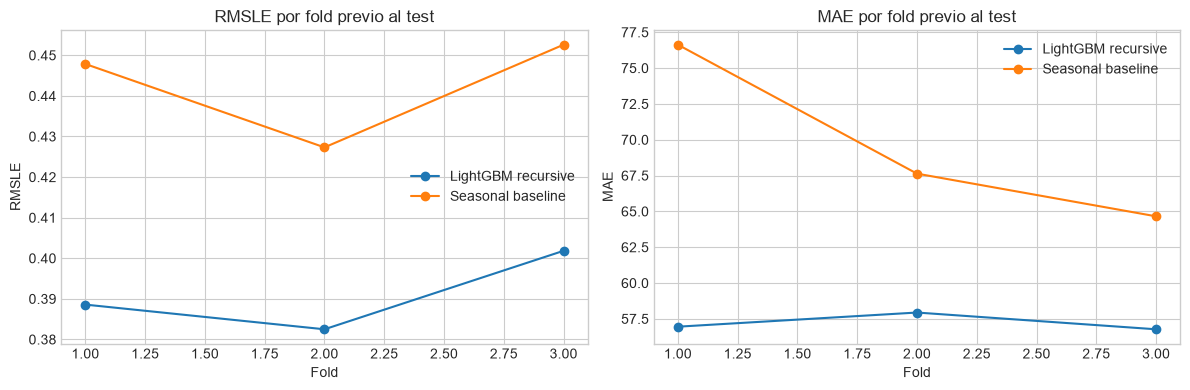

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for model_name, group in backtest_results.groupby("model"):
    axes[0].plot(group["fold"], group["RMSLE"], marker="o", label=model_name)
    axes[1].plot(group["fold"], group["MAE"], marker="o", label=model_name)

axes[0].set(title="RMSLE por fold previo al test", xlabel="Fold", ylabel="RMSLE")
axes[1].set(title="MAE por fold previo al test", xlabel="Fold", ylabel="MAE")
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()

### Permutation importance recursiva fuera de entrenamiento

La permutation importance tabular convencional no es comparable con
este forecast: reconstruir lags sobre la validación incorporaría ventas
reales que no existen al emitir el pronóstico. Aquí cada perturbación
vuelve a recorrer los 15 días. Sólo permuta features generadas por el
recorrido base, realimenta predicciones perturbadas y nunca usa ventas
reales para lags o rolling. Cada feature se permuta sólo entre series
de la misma fecha; los lags y rolling se reconstruyen primero desde la
historia del recorrido perturbado. La importancia es el aumento de
RMSLE y mide sensibilidad predictiva, no causalidad. Las features
constantes entre series de un mismo día tienen importancia cero por
construcción bajo este procedimiento.

In [9]:
from src.models.recursive_importance import recursive_permutation_importance

last_prepared = last_fold_result["prepared"]
permutation_table, permutation_predictions, permutation_trace = (
    recursive_permutation_importance(
        model=last_fold_result["model"],
        features_base=last_prepared["features_base"],
        train=last_prepared["train"],
        validation=last_prepared["validation"],
        validation_start=backtest_windows.iloc[-1]["validation_start"],
        validation_end=backtest_windows.iloc[-1]["validation_end"],
        model_features=MODEL_FEATURES,
        category_schema=last_fold_result["category_schema"],
        n_repeats=3,
        random_state=42,
    )
)
assert permutation_trace["date"].min() > last_prepared["train"]["date"].max()
assert len(permutation_predictions) == len(last_prepared["validation"])
display(permutation_table.head(15).round(6))

,feature,importance_mean,importance_std,baseline_RMSLE
0,rolling_mean_7,1.344647,0.004551,0.401833
1,lag_1,0.827994,0.002334,0.401833
2,onpromotion,0.433825,0.006144,0.401833
3,family,0.320672,0.000128,0.401833
4,lag_7,0.178697,0.003850,0.401833
5,rolling_mean_14,0.070253,0.000956,0.401833
6,rolling_mean_28,0.068358,0.000583,0.401833
7,store_nbr,0.028361,0.000343,0.401833
8,lag_14,0.028261,0.000621,0.401833
9,lag_28,0.011750,0.000225,0.401833


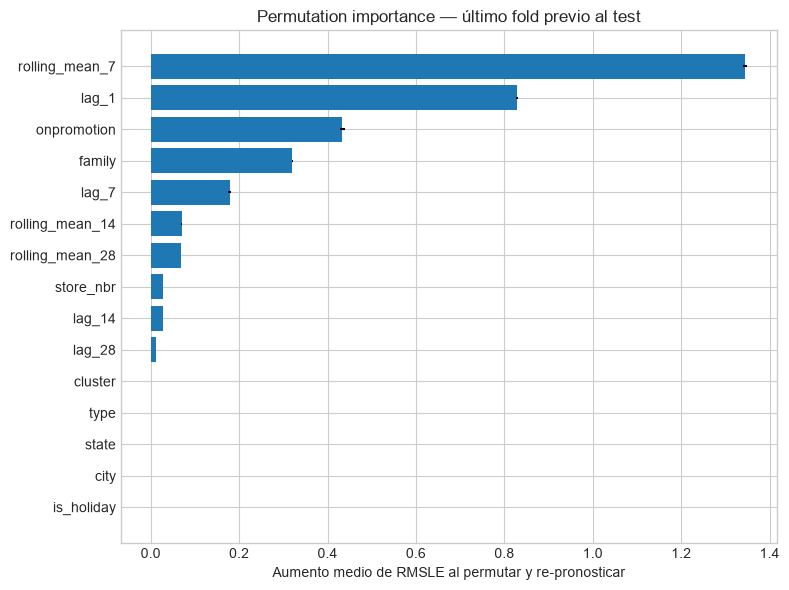

In [10]:
permutation_plot = permutation_table.head(15).sort_values("importance_mean")
plt.figure(figsize=(8, 6))
plt.barh(
    permutation_plot["feature"],
    permutation_plot["importance_mean"],
    xerr=permutation_plot["importance_std"],
)
plt.title("Permutation importance — último fold previo al test")
plt.xlabel("Aumento medio de RMSLE al permutar y re-pronosticar")
plt.tight_layout()
plt.show()

del permutation_predictions, permutation_trace
del last_fold_result, last_prepared
_ = gc.collect()

## Test final intocable

A partir de este punto `best_iteration` ya está fijado. Se reentrena con
toda la información disponible hasta el 31/07/2017 y se evalúa el test
01/08/2017–15/08/2017 una sola vez.

In [11]:
from src.models.experiment import run_final_test

final_result = run_final_test(
    datasets=datasets,
    train_end=FINAL_TRAIN_END,
    test_start=FINAL_TEST_START,
    test_end=FINAL_TEST_END,
    n_estimators=FINAL_N_ESTIMATORS,
)

final_summary = final_result["summary"]
display(final_summary.round(6))
print("Cold-start en test final:", len(final_result["prepared"]["cold_start_keys"]))
assert len(final_result["prepared"]["cold_start_keys"]) == 0

,model,RMSLE,MAE,MSE_signed,WAPE_pct,Bias_pct,Overprediction,Underprediction
0,Seasonal baseline,0.536571,85.477984,4.223710,17.830081,0.881035,1.163207e+06,1.053665e+06
1,LightGBM recursive,0.398867,65.176282,16.999931,13.595294,3.546061,1.065620e+06,6.247268e+05


Cold-start en test final: 0


### Comparación con la versión anterior

In [12]:
previous_results = pd.DataFrame(
    [
        {"model": "Seasonal baseline", "previous_RMSLE": 0.536571, "previous_MAE": 85.477984},
        {"model": "LightGBM recursive", "previous_RMSLE": 0.405895, "previous_MAE": 70.298360},
    ]
)
final_comparison = final_summary.merge(previous_results, on="model", how="left")
final_comparison["delta_RMSLE"] = (
    final_comparison["RMSLE"] - final_comparison["previous_RMSLE"]
)
final_comparison["delta_MAE"] = (
    final_comparison["MAE"] - final_comparison["previous_MAE"]
)
display(final_comparison.round(6))

,model,RMSLE,MAE,MSE_signed,WAPE_pct,Bias_pct,Overprediction,Underprediction,previous_RMSLE,previous_MAE,delta_RMSLE,delta_MAE
0,Seasonal baseline,0.536571,85.477984,4.223710,17.830081,0.881035,1.163207e+06,1.053665e+06,0.536571,85.477984,0.000000,-0.000000
1,LightGBM recursive,0.398867,65.176282,16.999931,13.595294,3.546061,1.065620e+06,6.247268e+05,0.405895,70.298360,-0.007028,-5.122078


## Diagnóstico comercial del test final

WAPE pondera el error absoluto por el volumen real; si un segmento no
tiene ventas, queda como `NaN` en vez de dividir por cero. Un sesgo
negativo indica subpredicción (riesgo potencial de faltantes) y uno
positivo sobrepredicción (riesgo potencial de sobrestock). Son riesgos
inferidos del forecast: sin inventario, quiebres ni costos no se afirma
que hayan ocurrido faltantes, pérdidas o excedentes reales.

RMSLE y WAPE responden preguntas diferentes: RMSLE enfatiza errores
relativos y reduce el peso de grandes volúmenes; WAPE refleja unidades
absolutas sobre el volumen total. Mejorar una no garantiza mejorar la
otra.

In [13]:
from src.models.experiment import prediction_metrics, segment_metrics

lgbm_eval = final_result["lgbm_eval"].copy()
baseline_eval = final_result["baseline_eval"].copy()
comparison_eval = lgbm_eval.merge(
    baseline_eval[["date", "store_nbr", "family", "pred_baseline"]],
    on=["date", "store_nbr", "family"],
    how="left",
    validate="one_to_one",
)
comparison_eval["horizon_day"] = (
    comparison_eval["date"] - FINAL_TEST_START
).dt.days + 1

daily_rows = []
for horizon_day, group in comparison_eval.groupby("horizon_day"):
    for model_name, prediction_col in [
        ("Seasonal baseline", "pred_baseline"),
        ("LightGBM recursive", "prediction"),
    ]:
        daily_rows.append({
            "horizon_day": horizon_day,
            "model": model_name,
            **prediction_metrics(group["sales"], group[prediction_col]),
        })
daily_diagnostics = pd.DataFrame(daily_rows)
display(daily_diagnostics.round(6))

,horizon_day,model,RMSLE,MAE,MSE_signed,WAPE_pct,Bias_pct,Overprediction,Underprediction
0,1,Seasonal baseline,0.528670,141.332613,-137.001396,24.720003,-23.962444,3744.336722,240619.751110
1,1,LightGBM recursive,0.363640,62.019171,-18.432489,10.847560,-3.223964,37680.686184,69550.460516
2,2,Seasonal baseline,0.541590,116.852812,-109.472908,20.942883,-19.620224,6379.926517,195658.584751
3,2,LightGBM recursive,0.377887,60.420124,-22.151161,10.828765,-3.970030,33083.518085,71382.875774
4,3,Seasonal baseline,0.529643,61.323535,-33.865337,14.562970,-8.042261,23737.612081,82290.780263
5,3,LightGBM recursive,0.387646,59.116050,28.429480,14.038741,6.751366,75683.110627,26528.539845
6,4,Seasonal baseline,0.536580,65.981509,-17.684043,13.781756,-3.693719,41753.158739,72328.869615
7,4,LightGBM recursive,0.409003,64.447827,17.488280,13.461412,3.652830,70833.764781,40596.527963
8,5,Seasonal baseline,0.475821,68.165595,10.101595,12.204524,1.808613,67661.985774,50196.328641
9,5,LightGBM recursive,0.371650,67.710648,41.840302,12.123069,7.491183,94706.796155,22364.913387


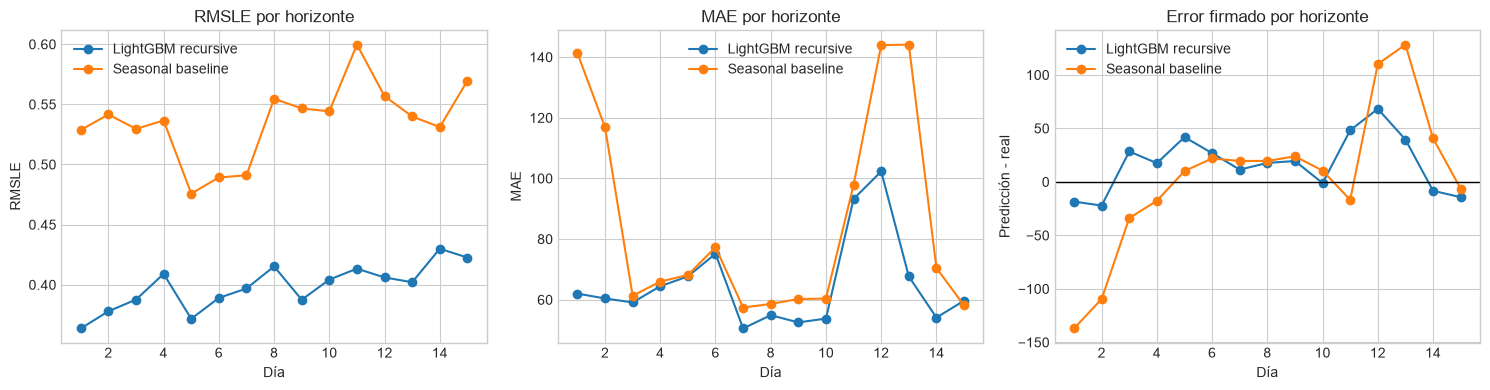

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for model_name, group in daily_diagnostics.groupby("model"):
    axes[0].plot(group["horizon_day"], group["RMSLE"], marker="o", label=model_name)
    axes[1].plot(group["horizon_day"], group["MAE"], marker="o", label=model_name)
    axes[2].plot(group["horizon_day"], group["MSE_signed"], marker="o", label=model_name)

axes[0].set(title="RMSLE por horizonte", xlabel="Día", ylabel="RMSLE")
axes[1].set(title="MAE por horizonte", xlabel="Día", ylabel="MAE")
axes[2].axhline(0, color="black", linewidth=1)
axes[2].set(title="Error firmado por horizonte", xlabel="Día", ylabel="Predicción - real")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

In [15]:
def compare_segments(data, group_cols):
    frames = []
    for model_name, prediction_col in [
        ("Seasonal baseline", "pred_baseline"),
        ("LightGBM recursive", "prediction"),
    ]:
        metrics = segment_metrics(data, prediction_col, group_cols)
        metrics["model"] = model_name
        frames.append(metrics)
    return pd.concat(frames, ignore_index=True)

store_diagnostics = compare_segments(comparison_eval, ["store_nbr"])
family_diagnostics = compare_segments(comparison_eval, ["family"])

display(store_diagnostics.sort_values("RMSLE", ascending=False).head(20).round(4))
display(family_diagnostics.sort_values("RMSLE", ascending=False).head(20).round(4))

,store_nbr,RMSLE,MAE,MSE_signed,WAPE_pct,Bias_pct,Overprediction,Underprediction,pct_zero_sales,pct_overpredicted,pct_underpredicted,n_obs,n_series,model
49,50,0.9653,117.6417,34.3131,18.4999,5.3959,36469.1597,19998.8520,6.6667,52.9167,44.7917,480,32,Seasonal baseline
47,48,0.8892,160.9699,-8.0900,20.5729,-1.0340,36691.1673,40574.3843,8.7500,44.1667,51.4583,480,32,Seasonal baseline
46,47,0.8856,187.0774,33.2630,16.5219,2.9377,52881.6972,36915.4684,5.4167,47.0833,51.2500,480,32,Seasonal baseline
43,44,0.8058,224.3215,107.2916,17.5258,8.3825,79587.1518,28087.1668,6.0417,57.2917,39.1667,480,32,Seasonal baseline
19,20,0.7529,133.8495,-73.4389,23.8595,-13.0909,14498.5404,49749.2103,10.6250,42.7083,51.2500,480,32,Seasonal baseline
8,9,0.7143,112.9300,-54.0505,19.1321,-9.1570,14131.0898,40075.3169,6.4583,42.5000,54.1667,480,32,Seasonal baseline
45,46,0.6850,164.7972,39.8432,18.5475,4.4842,49113.6944,29988.9602,4.5833,45.2083,51.2500,480,32,Seasonal baseline
48,49,0.6481,122.9806,46.3293,12.2239,4.6050,40634.3777,18396.3321,5.4167,56.8750,39.1667,480,32,Seasonal baseline
18,19,0.6403,43.2207,-8.0895,14.8146,-2.7728,8431.4890,12314.4277,11.8750,52.0833,41.0417,480,32,Seasonal baseline
17,18,0.6132,52.0034,8.1073,16.3387,2.5472,14426.5732,10535.0530,7.9167,53.5417,42.0833,480,32,Seasonal baseline


,family,RMSLE,MAE,MSE_signed,WAPE_pct,Bias_pct,Overprediction,Underprediction,pct_zero_sales,pct_overpredicted,pct_underpredicted,n_obs,n_series,model
31,SCHOOL AND OFFICE SUPPLIES,1.7674,57.1840,-56.5765,92.3259,-91.3453,246.0000,46073.0000,48.6420,22.7160,41.3580,810,54,Seasonal baseline
21,LINGERIE,0.7169,4.4750,-1.6978,56.7520,-21.5320,1124.7500,2500.0000,8.3951,47.4074,50.0000,810,54,Seasonal baseline
13,GROCERY II,0.6952,13.3926,5.3228,46.7083,18.5640,7579.7500,3268.2500,1.8519,60.0000,38.1481,810,54,Seasonal baseline
54,LINGERIE,0.6215,3.9432,-1.8147,50.0080,-23.0140,862.0555,2331.9579,8.3951,46.2963,53.7037,810,54,LightGBM recursive
46,GROCERY II,0.6120,11.0205,2.4860,38.4352,8.6703,5470.1292,3456.4562,1.8519,53.9506,46.0494,810,54,LightGBM recursive
14,HARDWARE,0.6022,1.1633,0.0213,80.4654,1.4731,479.7500,462.5000,37.4074,49.2593,37.7778,810,54,Seasonal baseline
19,LADIESWEAR,0.5952,4.8977,1.1811,39.2056,9.4542,2006.0000,1226.5000,16.2121,56.9697,36.5152,660,44,Seasonal baseline
64,SCHOOL AND OFFICE SUPPLIES,0.5902,32.7659,-18.3408,52.9019,-29.6121,5842.1332,20698.2105,48.6420,63.9506,35.9259,810,54,LightGBM recursive
2,BEAUTY,0.5833,2.9111,-1.4778,43.0213,-21.8391,580.5000,1777.5000,9.5062,39.1358,56.9136,810,54,Seasonal baseline
23,MAGAZINES,0.5804,3.0414,-0.9272,41.7472,-12.7267,856.2500,1607.2500,13.8272,46.6667,48.2716,810,54,Seasonal baseline


### Familias difíciles y patrones ADI/CV²

La clasificación se calcula exclusivamente con train hasta 31/07. Se
comparan ambos modelos para LINGERIE, GROCERY II, demanda intermitente y
lumpy, incluyendo ceros, frecuencia del signo del error, magnitudes y
tamaños de muestra. Esto genera evidencia para decidir más adelante si
vale la pena probar un hurdle; aquí no se entrena ningún segundo modelo.

In [16]:
from src.features.demand_classification import build_demand_profile

train_demand_profile = build_demand_profile(final_result["prepared"]["train"])
demand_eval = comparison_eval.merge(
    train_demand_profile[
        ["store_nbr", "family", "tipo_demanda", "pct_ceros"]
    ],
    on=["store_nbr", "family"],
    how="left",
    validate="many_to_one",
)
assert demand_eval["tipo_demanda"].notna().all()

demand_diagnostics = compare_segments(demand_eval, ["tipo_demanda"])
difficult_demand = demand_diagnostics.loc[
    demand_diagnostics["tipo_demanda"].isin(["Intermitente", "Lumpy"])
].copy()
difficult_families = family_diagnostics.loc[
    family_diagnostics["family"].isin(["LINGERIE", "GROCERY II"])
].copy()

display(demand_diagnostics.round(4))
print("Foco: demanda intermitente y lumpy")
display(difficult_demand.round(4))
print("Foco: LINGERIE y GROCERY II")
display(difficult_families.round(4))

profile_sizes = (
    train_demand_profile.groupby("tipo_demanda", as_index=False)
    .agg(
        series=("family", "size"),
        historical_zero_pct=("pct_ceros", "mean"),
    )
)
display(profile_sizes.round(4))

,tipo_demanda,RMSLE,MAE,MSE_signed,WAPE_pct,Bias_pct,Overprediction,Underprediction,pct_zero_sales,pct_overpredicted,pct_underpredicted,n_obs,n_series,model
0,Errática,0.5669,71.4859,0.0177,16.2890,0.0040,154447.8208,154371.2160,2.3380,51.0417,47.7778,4320,288,Seasonal baseline
1,Intermitente,0.4487,18.2013,5.7624,18.9617,6.0032,73508.6029,38156.1740,31.5892,50.2200,33.1540,6135,409,Seasonal baseline
2,Lumpy,0.9446,16.5281,-11.4875,65.3811,-45.4417,10245.0060,56941.6485,25.4367,43.7884,39.5818,4065,271,Seasonal baseline
3,Regular,0.3263,151.4850,10.5834,17.5628,1.2270,925005.2808,804195.7550,0.3066,52.3697,47.0696,11415,761,Seasonal baseline
4,Errática,0.4910,58.5186,4.6791,13.3343,1.0662,136507.0061,116293.4219,2.3380,49.6528,50.3472,4320,288,LightGBM recursive
5,Intermitente,0.4009,15.7370,4.7549,16.3945,4.9536,62859.1001,33687.6757,31.5892,61.3692,38.5982,6135,409,LightGBM recursive
6,Lumpy,0.5451,11.0332,-5.5794,43.6446,-22.0707,11084.8403,33765.0443,25.4367,53.3333,46.6667,4065,271,LightGBM recursive
7,Regular,0.2793,113.5479,36.2846,13.1645,4.2068,855169.0956,440980.6780,0.3066,56.2681,43.7319,11415,761,LightGBM recursive


Foco: demanda intermitente y lumpy


,tipo_demanda,RMSLE,MAE,MSE_signed,WAPE_pct,Bias_pct,Overprediction,Underprediction,pct_zero_sales,pct_overpredicted,pct_underpredicted,n_obs,n_series,model
1,Intermitente,0.4487,18.2013,5.7624,18.9617,6.0032,73508.6029,38156.1740,31.5892,50.2200,33.1540,6135,409,Seasonal baseline
2,Lumpy,0.9446,16.5281,-11.4875,65.3811,-45.4417,10245.0060,56941.6485,25.4367,43.7884,39.5818,4065,271,Seasonal baseline
5,Intermitente,0.4009,15.7370,4.7549,16.3945,4.9536,62859.1001,33687.6757,31.5892,61.3692,38.5982,6135,409,LightGBM recursive
6,Lumpy,0.5451,11.0332,-5.5794,43.6446,-22.0707,11084.8403,33765.0443,25.4367,53.3333,46.6667,4065,271,LightGBM recursive


Foco: LINGERIE y GROCERY II


,family,RMSLE,MAE,MSE_signed,WAPE_pct,Bias_pct,Overprediction,Underprediction,pct_zero_sales,pct_overpredicted,pct_underpredicted,n_obs,n_series,model
13,GROCERY II,0.6952,13.3926,5.3228,46.7083,18.5640,7579.7500,3268.2500,1.8519,60.0000,38.1481,810,54,Seasonal baseline
21,LINGERIE,0.7169,4.4750,-1.6978,56.7520,-21.5320,1124.7500,2500.0000,8.3951,47.4074,50.0000,810,54,Seasonal baseline
46,GROCERY II,0.6120,11.0205,2.4860,38.4352,8.6703,5470.1292,3456.4562,1.8519,53.9506,46.0494,810,54,LightGBM recursive
54,LINGERIE,0.6215,3.9432,-1.8147,50.0080,-23.0140,862.0555,2331.9579,8.3951,46.2963,53.7037,810,54,LightGBM recursive


,tipo_demanda,series,historical_zero_pct
0,Errática,288,6.7301
1,Intermitente,409,54.4862
2,Lumpy,271,51.6613
3,Regular,761,1.5351


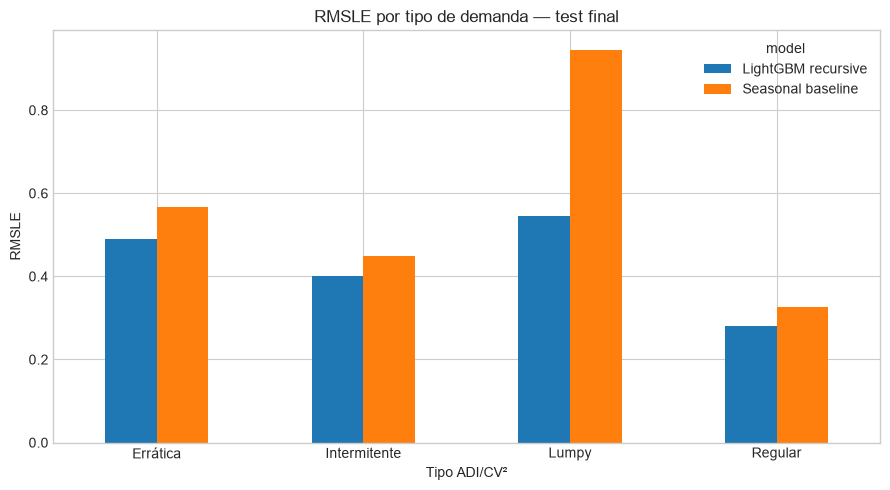

In [17]:
pivot = demand_diagnostics.pivot(
    index="tipo_demanda", columns="model", values="RMSLE"
)
pivot.plot(kind="bar", figsize=(9, 5))
plt.title("RMSLE por tipo de demanda — test final")
plt.xlabel("Tipo ADI/CV²")
plt.ylabel("RMSLE")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Sensibilidad a promociones futuras

En el escenario de Corporación Favorita se asume que `onpromotion`
representa un plan promocional conocido antes de los 15 días. En una
empresa real sólo sería admisible si proviene del calendario comercial
aprobado; un registro completado retrospectivamente no estaría
disponible y no debería usarse.

Como sensibilidad, se mantiene el mismo modelo ya fijado y se vuelve a
pronosticar el test forzando `onpromotion=0`. No se reentrena ni se usa
la venta real para construir features. La comparación mide cuánto
depende el forecast de disponer del plan, no estima causalidad de las
promociones.

In [18]:
from src.models.recursive_forecast import recursive_forecast

def without_future_promotions(X_day, keys, current_date):
    X_day["onpromotion"] = 0
    return X_day

no_promo_predictions = recursive_forecast(
    model=final_result["model"],
    features_base=final_result["prepared"]["features_base"],
    train=final_result["prepared"]["train"],
    validation_start=FINAL_TEST_START,
    validation_end=FINAL_TEST_END,
    model_features=MODEL_FEATURES,
    category_schema=final_result["category_schema"],
    feature_transform=without_future_promotions,
).rename(columns={"prediction": "prediction_no_future_promo"})

promotion_sensitivity = comparison_eval.merge(
    no_promo_predictions,
    on=["date", "store_nbr", "family"],
    how="left",
    validate="one_to_one",
)
promotion_rows = []
for scenario, prediction_col in [
    ("Plan futuro disponible", "prediction"),
    ("Sin información promocional futura", "prediction_no_future_promo"),
]:
    promotion_rows.append({
        "scenario": scenario,
        "forecast_total": promotion_sensitivity[prediction_col].sum(),
        **prediction_metrics(
            promotion_sensitivity["sales"],
            promotion_sensitivity[prediction_col],
        ),
    })
promotion_sensitivity_summary = pd.DataFrame(promotion_rows)
display(promotion_sensitivity_summary.round(4))
print(
    "Filas con promoción planificada en el horizonte:",
    int(final_result["prepared"]["features_base"].loc[
        lambda x: x["date"].between(FINAL_TEST_START, FINAL_TEST_END),
        "onpromotion",
    ].gt(0).sum()),
)

,scenario,forecast_total,RMSLE,MAE,MSE_signed,WAPE_pct,Bias_pct,Overprediction,Underprediction
0,Plan futuro disponible,1.287422e+07,0.3989,65.1763,16.9999,13.5953,3.5461,1.065620e+06,6.247268e+05
1,Sin información promocional futura,1.118900e+07,0.4925,79.6144,-47.9787,16.6070,-10.0080,4.102364e+05,1.654563e+06


Filas con promoción planificada en el horizonte: 11784


### Feature importance del modelo final

In [19]:
final_model = final_result["model"]
feature_importance = pd.DataFrame(
    {
        "feature": MODEL_FEATURES,
        "gain": final_model.booster_.feature_importance(importance_type="gain"),
        "splits": final_model.booster_.feature_importance(importance_type="split"),
    }
)
feature_importance["gain_pct"] = (
    feature_importance["gain"] / feature_importance["gain"].sum() * 100
)
feature_importance = feature_importance.sort_values(
    "gain", ascending=False
).reset_index(drop=True)
display(feature_importance.head(15).round(6))

print(
    "Gain y split describen el uso interno de features por LightGBM; "
    "no miden causalidad."
)

,feature,gain,splits,gain_pct
0,rolling_mean_7,1.069960e+08,4363,56.760514
1,lag_7,6.279189e+07,3541,33.310583
2,lag_1,7.266077e+06,4737,3.854594
3,rolling_mean_14,6.387322e+06,1660,3.388422
4,lag_14,1.224870e+06,2525,0.649783
5,family,1.154850e+06,10220,0.612639
6,is_new_year_closure,5.769036e+05,279,0.306043
7,lag_28,4.998494e+05,2549,0.265166
8,day_of_week,3.494229e+05,3617,0.185366
9,day,2.417808e+05,3966,0.128263


Gain y split describen el uso interno de features por LightGBM; no miden causalidad.


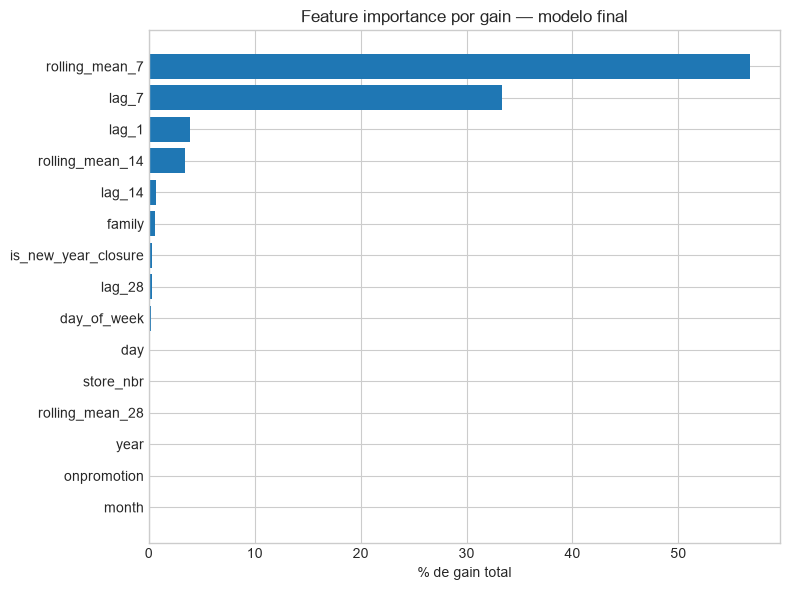

In [20]:
importance_plot = feature_importance.head(15).sort_values("gain_pct")
plt.figure(figsize=(8, 6))
plt.barh(importance_plot["feature"], importance_plot["gain_pct"])
plt.title("Feature importance por gain — modelo final")
plt.xlabel("% de gain total")
plt.tight_layout()
plt.show()

## Takeaways y controles finales

In [21]:
assert final_result["prepared"]["train"]["date"].max() == FINAL_TRAIN_END
assert comparison_eval["date"].min() == FINAL_TEST_START
assert comparison_eval["date"].max() == FINAL_TEST_END
assert comparison_eval["date"].nunique() == HORIZON_DAYS
assert comparison_eval["prediction"].notna().all()
assert np.isfinite(comparison_eval["prediction"]).all()
assert (comparison_eval["prediction"] >= 0).all()
assert set(final_result["category_schema"]) == set(CATEGORICAL_FEATURES)

print("RESULTADO FINAL")
display(final_comparison.round(6))
print("BACKTESTING")
display(backtest_aggregate.round(6))
print("Árboles seleccionados:", FINAL_N_ESTIMATORS)
print("Universo vs versión anterior: 0 diferencias")
print("Cold-start en test final: 0 series")
print("✓ Test final cubierto completamente y evaluado en forma recursiva")

RESULTADO FINAL


,model,RMSLE,MAE,MSE_signed,WAPE_pct,Bias_pct,Overprediction,Underprediction,previous_RMSLE,previous_MAE,delta_RMSLE,delta_MAE
0,Seasonal baseline,0.536571,85.477984,4.223710,17.830081,0.881035,1.163207e+06,1.053665e+06,0.536571,85.477984,0.000000,-0.000000
1,LightGBM recursive,0.398867,65.176282,16.999931,13.595294,3.546061,1.065620e+06,6.247268e+05,0.405895,70.298360,-0.007028,-5.122078


BACKTESTING


,model,RMSLE_mean,RMSLE_std,MAE_mean,MAE_std,WAPE_mean,WAPE_std,signed_error_mean,signed_error_std,bias_pct_mean
0,LightGBM recursive,0.390971,0.009886,57.220365,0.629283,11.579518,0.215515,-4.462179,15.685443,-0.914375
1,Seasonal baseline,0.442592,0.013444,69.639352,6.235829,14.099394,1.397049,10.988712,16.210790,2.265812


Árboles seleccionados: 1029
Universo vs versión anterior: 0 diferencias
Cold-start en test final: 0 series
✓ Test final cubierto completamente y evaluado en forma recursiva
